In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from itertools import combinations
from pathlib import Path


In [2]:
dados_path = Path("data")
df_o = pd.read_excel(dados_path /'Cópia 2 de [PT-BR] Script do Questionário (respostas) (1).xlsx')

df = df_o[:]

df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace('\n', '', regex=True)

print(len(df))

print(df.columns.tolist())

95
['Carimbo de data/hora', 'Após ter recebido esclarecimentos sobre a natureza da pesquisa, seus objetivos e métodos, eu declaro que sou maior de 18 anos e aceito participar por meio do formulário de participação, conforme as disposições da Lei Geral de Proteção de Dados (Lei nº 13.709/2018).Em caso de resposta negativa, o formulário será encerrado, garantindo assim o respeito à autonomia e privacidade dos participantes, conforme estabelecido pela legislação vigente.', 'Qual é a sua idade?', 'Em qual estado do Brasil você mora atualmente?', 'Qual é o seu gênero?', 'Qual é o seu nível de educação formal concluída?', 'Qual seu modelo de trabalho?', 'Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?', 'Por favor, indique a senioridade da posição que ocupa.', 'Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?', 'Quantos anos de experiência você tem em funções relacionadas a Segurança de Softwa

In [3]:
print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].unique())


df = df[~(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'] == 'Nunca tive experiência direta e nem indireta com segurança no processo de desenvolvimento de software')]

print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].unique())
print(df.shape)

['Nunca tive experiência direta e nem indireta com segurança no processo de desenvolvimento de software'
 'Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.'
 'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.']
['Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.'
 'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.']
(83, 102)


In [4]:
df.isna().sum()

Carimbo de data/hora                                                                                                                                                                                                                                                                                                                                                                                                                                            0
Após ter recebido esclarecimentos sobre a natureza da pesquisa, seus objetivos e métodos, eu declaro que sou maior de 18 anos e aceito participar por meio do formulário de participação, conforme as disposições da Lei Geral de Proteção de Dados (Lei nº 13.709/2018).Em caso de resposta negativa, o formulário será encerrado, garantindo assim o respeito à autonomia e privacidade dos participantes, conforme estabelecido pela legislação vigente.     0
Qual é a sua idade?                                                                                 

In [5]:
df.shape

(83, 102)

Analises

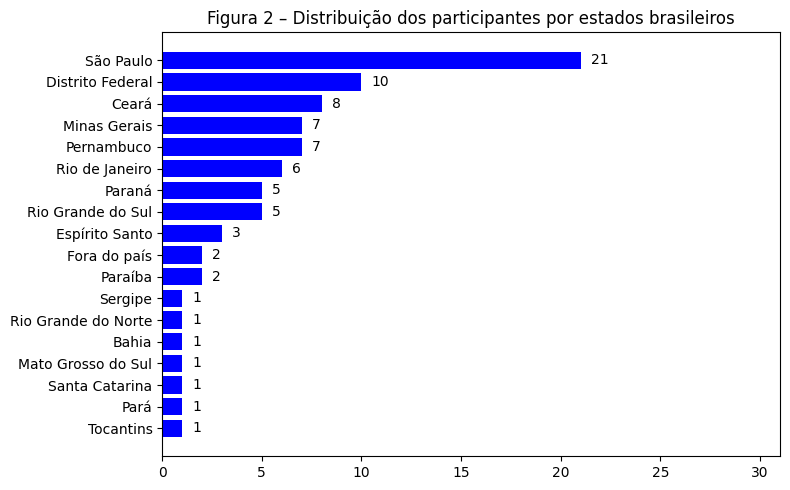

In [6]:
coluna_estado = "Em qual estado do Brasil você mora atualmente?"  # <-- altere se necessário

# Conta a quantidade de participantes por estado
contagem_estados = df[coluna_estado].value_counts().sort_values(ascending=True)

# Cria o gráfico de barras horizontais
plt.figure(figsize=(8, 5))
plt.barh(contagem_estados.index, contagem_estados.values, color='blue')

# Adiciona os rótulos de valores
for i, v in enumerate(contagem_estados.values):
    plt.text(v + 0.5, i, str(v), va='center')

# Títulos e rótulos
plt.title("Figura 2 – Distribuição dos participantes por estados brasileiros", fontsize=12)
plt.xlabel("")
plt.ylabel("")
plt.xlim(0, contagem_estados.values.max() + 10)
plt.tight_layout()
plt.show()

In [7]:
colunas_alvo = {
    "Gênero": "Qual é o seu gênero?",  # exemplo: pode estar como "Qual é o seu gênero?"
    "Faixa etária": "Qual é a sua idade?",  # exemplo: "Qual é a sua faixa etária?"
    "Formação acadêmica": "Qual é o seu nível de educação formal concluída?"  # exemplo: "Qual é a sua formação acadêmica?"
}

# Função para gerar a sumarização
def sumarizar_coluna(df, coluna):
    total = df[coluna].notna().sum()  # total de respostas válidas
    contagem = df[coluna].value_counts().sort_values(ascending=False)
    porcentagem = (contagem / total) * 100
    resumo = pd.DataFrame({
        "Quantidade": contagem,
        "Porcentagem (%)": porcentagem.round(1)
    })
    return resumo

# Gera as tabelas de resumo
for nome_exibicao, nome_coluna in colunas_alvo.items():
    print(f"\n===== {nome_exibicao.upper()} =====")
    if nome_coluna in df.columns:
        print(sumarizar_coluna(df, nome_coluna))
    else:
        print(f"❌ Coluna '{nome_coluna}' não encontrada. Verifique o nome exato no arquivo.")


===== GÊNERO =====
                       Quantidade  Porcentagem (%)
Qual é o seu gênero?                              
Homem                          70             84.3
Mulher                         12             14.5
Prefiro não responder           1              1.2

===== FAIXA ETÁRIA =====
                     Quantidade  Porcentagem (%)
Qual é a sua idade?                             
25 - 34 anos                 44             53.0
18 - 24 anos                 22             26.5
35 - 44 anos                 14             16.9
45 - 54 anos                  2              2.4
55 - 64 anos                  1              1.2

===== FORMAÇÃO ACADÊMICA =====
                                                  Quantidade  Porcentagem (%)
Qual é o seu nível de educação formal concluída?                             
Ensino Superior                                           31             37.3
Ensino Médio                                              19             22.9
Especializaç

In [8]:
colunas_alvo = {
    "Modelo": "Qual seu modelo de trabalho?",  # exemplo: pode estar como "Qual é o seu gênero?"
    "Senioridade": "Por favor, indique a senioridade da posição que ocupa."  # exemplo: "Qual é a sua formação acadêmica?"
}

# Função para gerar a sumarização
def sumarizar_coluna(df, coluna):
    total = df[coluna].notna().sum()  # total de respostas válidas
    contagem = df[coluna].value_counts().sort_values(ascending=False)
    porcentagem = (contagem / total) * 100
    resumo = pd.DataFrame({
        "Quantidade": contagem,
        "Porcentagem (%)": porcentagem.round(1)
    })
    return resumo

# Gera as tabelas de resumo
for nome_exibicao, nome_coluna in colunas_alvo.items():
    print(f"\n===== {nome_exibicao.upper()} =====")
    if nome_coluna in df.columns:
        print(sumarizar_coluna(df, nome_coluna))
    else:
        print(f"❌ Coluna '{nome_coluna}' não encontrada. Verifique o nome exato no arquivo.")


===== MODELO =====
                              Quantidade  Porcentagem (%)
Qual seu modelo de trabalho?                             
Remoto                                52             62.7
Híbrido                               26             31.3
Presencial                             5              6.0

===== SENIORIDADE =====
                                                    Quantidade  \
Por favor, indique a senioridade da posição que...               
Sênior (10+ anos)                                           34   
Júnior (até 5 anos)                                         24   
Pleno (6 a 9 anos)                                          16   
Estagiário                                                   9   

                                                    Porcentagem (%)  
Por favor, indique a senioridade da posição que...                   
Sênior (10+ anos)                                              41.0  
Júnior (até 5 anos)                                       

In [9]:
coluna_papeis = "Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?"

# === 3️⃣ Remover linhas vazias ===
df = df.dropna(subset=[coluna_papeis])

# Número total de participantes válidos
total_participantes = len(df)

# === 4️⃣ Corrigir respostas com vírgulas dentro de parênteses ===
def proteger_parenteses(texto):
    # Substitui vírgulas dentro de parênteses por um caractere temporário
    return re.sub(r"\(([^)]*)\)", lambda m: "(" + m.group(1).replace(",", "|") + ")", texto)

corrigido = df[coluna_papeis].apply(proteger_parenteses)

# === 5️⃣ Separar múltiplas respostas ===
todas_respostas = corrigido.str.split(",").explode().str.strip()
todas_respostas = todas_respostas.str.replace("|", ",", regex=False)

# === 6️⃣ Contar quantidade de cada papel ===
contagem = todas_respostas.value_counts().reset_index()
contagem.columns = ["Papel", "Quantidade"]

# === 7️⃣ Calcular porcentagem baseada no total de participantes ===
contagem["Porcentagem"] = (contagem["Quantidade"] / total_participantes * 100).round(2)

# === 8️⃣ Exibir resultado ===
print(f"\n=== Distribuição de Papéis (baseado em {total_participantes} participantes) ===\n")
print(contagem)

# === 9️⃣ (Opcional) Salvar em Excel ===
results_path = Path('results')
contagem.to_excel(results_path / "analise_papeis.xlsx", index=False)
print("\nArquivo 'analise_papeis.xlsx' salvo com sucesso!")


=== Distribuição de Papéis (baseado em 83 participantes) ===

                                       Papel  Quantidade  Porcentagem
0                          Security engineer          40        48.19
1                            DevOps engineer          27        32.53
2                         Penetration tester          26        31.33
3   Developer (Backend, frontend, fullstack)          12        14.46
4                         Solution Architect           8         9.64
5             Project Lead / Project Manager           6         7.23
6                             Data Scientist           4         4.82
7                           Privacy engineer           2         2.41
8                                     AppSec           1         1.20
9                              Cryptographer           1         1.20
10                    Arquiteto de Segurança           1         1.20
11                            UX/UI designer           1         1.20
12                Sustentaç

In [10]:
coluna_papeis = "Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?"

# === 3️⃣ Remover linhas vazias ===
df = df.dropna(subset=[coluna_papeis])

# === 4️⃣ Corrigir vírgulas dentro de parênteses ===
def proteger_parenteses(texto):
    return re.sub(r"\(([^)]*)\)", lambda m: "(" + m.group(1).replace(",", "|") + ")", texto)

corrigido = df[coluna_papeis].apply(proteger_parenteses)

# === 5️⃣ Separar respostas múltiplas ===
df["Papeis_lista"] = corrigido.apply(lambda x: [p.strip().replace("|", ",") for p in x.split(",")])

# === 6️⃣ Criar uma lista de todos os papéis únicos ===
todos_papeis = sorted(set([p for sublist in df["Papeis_lista"] for p in sublist]))

# === 7️⃣ Calcular coocorrência ===
coocorrencias = []

for papel1, papel2 in combinations(todos_papeis, 2):
    # Contar quantas pessoas marcaram ambos
    ambos = df["Papeis_lista"].apply(lambda lista: papel1 in lista and papel2 in lista).sum()
    # Contar quantas pessoas marcaram o primeiro
    total_papel1 = df["Papeis_lista"].apply(lambda lista: papel1 in lista).sum()

    if total_papel1 > 0:
        porcentagem = (ambos / total_papel1) * 100
        coocorrencias.append([papel1, papel2, ambos, round(porcentagem, 2)])

# === 8️⃣ Transformar em DataFrame ===
cooc_df = pd.DataFrame(coocorrencias, columns=["Papel A", "Papel B", "Quantidade em comum", "% dos que têm A que também têm B"])

# === 9️⃣ Ordenar pelas coocorrências mais fortes ===
cooc_df = cooc_df.sort_values(by="% dos que têm A que também têm B", ascending=False).reset_index(drop=True)

# === 🔟 Mostrar as principais correlações ===
print("\n=== Principais combinações de papéis ===\n")
print(cooc_df.head(20))

# (Opcional) Salvar em Excel
results_path = Path('results')
cooc_df.to_excel(results_path /"analise_coocorrencia_papeis.xlsx", index=False)
print("\nArquivo 'analise_coocorrencia_papeis.xlsx' salvo com sucesso!")


=== Principais combinações de papéis ===

                                     Papel A  \
0                                     AppSec   
1                         Appsec & DevSecOps   
2                              Cryptographer   
3                         Appsec & DevSecOps   
4                      Requirements Engineer   
5                                     AppSec   
6                           Privacy engineer   
7                              Product owner   
8                         Appsec & DevSecOps   
9                              Product owner   
10                            Data Scientist   
11                        Penetration tester   
12                            Data Scientist   
13            Project Lead / Project Manager   
14                           DevOps engineer   
15                           DevOps engineer   
16                            Data Scientist   
17                            Data Scientist   
18                            Data Scientist 

In [11]:
colunas_alvo = {
    "ExpDS": "Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?",  # exemplo: pode estar como "Qual é o seu gênero?"
    "ExpSS": "Quantos anos de experiência você tem em funções relacionadas a Segurança de Software?"  # exemplo: "Qual é a sua formação acadêmica?"
}

# Função para gerar a sumarização
def sumarizar_coluna(df, coluna):
    total = df[coluna].notna().sum()  # total de respostas válidas
    contagem = df[coluna].value_counts().sort_values(ascending=False)
    porcentagem = (contagem / total) * 100
    resumo = pd.DataFrame({
        "Quantidade": contagem,
        "Porcentagem (%)": porcentagem.round(1)
    })
    return resumo

# Gera as tabelas de resumo
for nome_exibicao, nome_coluna in colunas_alvo.items():
    print(f"\n===== {nome_exibicao.upper()} =====")
    if nome_coluna in df.columns:
        print(sumarizar_coluna(df, nome_coluna))
    else:
        print(f"❌ Coluna '{nome_coluna}' não encontrada. Verifique o nome exato no arquivo.")


===== EXPDS =====
                                                    Quantidade  \
Quantos anos de experiência você tem em funções...               
Entre 7 e 14 anos                                           32   
Entre 1 e 3 anos                                            24   
Entre 4 e 5 anos                                            16   
Mais de 15 anos                                              8   
Menos de 1 ano                                               3   

                                                    Porcentagem (%)  
Quantos anos de experiência você tem em funções...                   
Entre 7 e 14 anos                                              38.6  
Entre 1 e 3 anos                                               28.9  
Entre 4 e 5 anos                                               19.3  
Mais de 15 anos                                                 9.6  
Menos de 1 ano                                                  3.6  

===== EXPSS =====
         

In [12]:
coluna_papeis = "Quais são os tipos de sistemas que você trabalha?"

# === 3️⃣ Remover linhas vazias ===
df = df.dropna(subset=[coluna_papeis])

# Número total de participantes válidos
total_participantes = len(df)

# === 4️⃣ Corrigir respostas com vírgulas dentro de parênteses ===
def proteger_parenteses(texto):
    # Substitui vírgulas dentro de parênteses por um caractere temporário
    return re.sub(r"\(([^)]*)\)", lambda m: "(" + m.group(1).replace(",", "|") + ")", texto)

corrigido = df[coluna_papeis].apply(proteger_parenteses)

# === 5️⃣ Separar múltiplas respostas ===
todas_respostas = corrigido.str.split(",").explode().str.strip()
todas_respostas = todas_respostas.str.replace("|", ",", regex=False)

# === 6️⃣ Contar quantidade de cada papel ===
contagem = todas_respostas.value_counts().reset_index()
contagem.columns = ["Papel", "Quantidade"]

# === 7️⃣ Calcular porcentagem baseada no total de participantes ===
contagem["Porcentagem"] = (contagem["Quantidade"] / total_participantes * 100).round(2)

# === 8️⃣ Exibir resultado ===
print(f"\n=== Distribuição de Papéis (baseado em {total_participantes} participantes) ===\n")
print(contagem)

# === 9️⃣ (Opcional) Salvar em Excel ===
results_path = Path('results')
contagem.to_excel(results_path / "analise_papeis.xlsx", index=False)
print("\nArquivo 'analise_papeis.xlsx' salvo com sucesso!")


=== Distribuição de Papéis (baseado em 83 participantes) ===

                                                Papel  Quantidade  Porcentagem
0                   Aplicações web (Web applications)          74        89.16
1             Aplicações móveis (Mobile applications)          42        50.60
2           Sistemas Operacionais (Operating Systems)          33        39.76
3           Aplicações desktop (Desktop applications)          32        38.55
4   Ferramentas para desenvolvedores (Developer to...          29        34.94
5       Aplicações embarcadas (Embedded applications)          16        19.28
6                             Middleware (Middleware)          15        18.07
7                        Não atuo com desenvolvimento           1         1.20
8                                               Todas           1         1.20
9                                                 API           1         1.20
10                              Ferramentas de AppSec           1   

In [13]:
coluna_papeis = "Quais são os domínios dos sistemas que você trabalha atualmente?"

# === 3️⃣ Remover linhas vazias ===
df = df.dropna(subset=[coluna_papeis])

# Número total de participantes válidos
total_participantes = len(df)

# === 4️⃣ Corrigir respostas com vírgulas dentro de parênteses ===
def proteger_parenteses(texto):
    # Substitui vírgulas dentro de parênteses por um caractere temporário
    return re.sub(r"\(([^)]*)\)", lambda m: "(" + m.group(1).replace(",", "|") + ")", texto)

corrigido = df[coluna_papeis].apply(proteger_parenteses)

# === 5️⃣ Separar múltiplas respostas ===
todas_respostas = corrigido.str.split(",").explode().str.strip()
todas_respostas = todas_respostas.str.replace("|", ",", regex=False)

# === 6️⃣ Contar quantidade de cada papel ===
contagem = todas_respostas.value_counts().reset_index()
contagem.columns = ["Papel", "Quantidade"]

# === 7️⃣ Calcular porcentagem baseada no total de participantes ===
contagem["Porcentagem"] = (contagem["Quantidade"] / total_participantes * 100).round(2)

# === 8️⃣ Exibir resultado ===
print(f"\n=== Distribuição de Papéis (baseado em {total_participantes} participantes) ===\n")
print(contagem)

# === 9️⃣ (Opcional) Salvar em Excel ===
results_path = Path('results')
contagem.to_excel(results_path / "analise_papeis.xlsx", index=False)
print("\nArquivo 'analise_papeis.xlsx' salvo com sucesso!")


=== Distribuição de Papéis (baseado em 83 participantes) ===

                                                Papel  Quantidade  Porcentagem
0               Bancos/Financeiro (Banking/Financial)          37        44.58
1             Defesa & Segurança (Defense & Security)          35        42.17
2                Vendas/E-commerce (Sales/E-commerce)          28        33.73
3                Telecomunicações (Telecommunication)          14        16.87
4                                Educação (Education)          13        15.66
5                                  Saúde (Healthcare)          12        14.46
6                                 Seguros (Insurance)           6         7.23
7                               Logística (Logistics)           6         7.23
8                      Entretenimento (Entertainment)           5         6.02
9   Sistemas embarcados em Automotivo ou Aviônica ...           2         2.41
10                                         Transporte           1   

In [14]:
coluna_papeis = "Qual é o setor da organização para qual você trabalha atualmente?"

# === 3️⃣ Remover linhas vazias ===
df = df.dropna(subset=[coluna_papeis])

# Número total de participantes válidos
total_participantes = len(df)

# === 4️⃣ Corrigir respostas com vírgulas dentro de parênteses ===
def proteger_parenteses(texto):
    # Substitui vírgulas dentro de parênteses por um caractere temporário
    return re.sub(r"\(([^)]*)\)", lambda m: "(" + m.group(1).replace(",", "|") + ")", texto)

corrigido = df[coluna_papeis].apply(proteger_parenteses)

# === 5️⃣ Separar múltiplas respostas ===
todas_respostas = corrigido.str.split(",").explode().str.strip()
todas_respostas = todas_respostas.str.replace("|", ",", regex=False)

# === 6️⃣ Contar quantidade de cada papel ===
contagem = todas_respostas.value_counts().reset_index()
contagem.columns = ["Papel", "Quantidade"]

# === 7️⃣ Calcular porcentagem baseada no total de participantes ===
contagem["Porcentagem"] = (contagem["Quantidade"] / total_participantes * 100).round(2)

# === 8️⃣ Exibir resultado ===
print(f"\n=== Distribuição de Papéis (baseado em {total_participantes} participantes) ===\n")
print(contagem)

# === 9️⃣ (Opcional) Salvar em Excel ===
results_path = Path('results')
contagem.to_excel(results_path / "analise_papeis.xlsx", index=False)
print("\nArquivo 'analise_papeis.xlsx' salvo com sucesso!")


=== Distribuição de Papéis (baseado em 83 participantes) ===

                                    Papel  Quantidade  Porcentagem
0                           Setor privado          70        84.34
1                           Setor público          11        13.25
2                                 Startup           5         6.02
3  Projetos de pesquisa e desenvolvimento           3         3.61
4                                Autônomo           3         3.61
5         Organização sem fins lucrativos           1         1.20
6                                 Aviação           1         1.20

Arquivo 'analise_papeis.xlsx' salvo com sucesso!


In [15]:
colunas_alvo = {
    "TamanhoEmp": "Qual o tamanho da empresa para a qual você trabalha atualmente?",  # exemplo: pode estar como "Qual é o seu gênero?"
}

# Função para gerar a sumarização
def sumarizar_coluna(df, coluna):
    total = df[coluna].notna().sum()  # total de respostas válidas
    contagem = df[coluna].value_counts().sort_values(ascending=False)
    porcentagem = (contagem / total) * 100
    resumo = pd.DataFrame({
        "Quantidade": contagem,
        "Porcentagem (%)": porcentagem.round(1)
    })
    return resumo

# Gera as tabelas de resumo
for nome_exibicao, nome_coluna in colunas_alvo.items():
    print(f"\n===== {nome_exibicao.upper()} =====")
    if nome_coluna in df.columns:
        print(sumarizar_coluna(df, nome_coluna))
    else:
        print(f"❌ Coluna '{nome_coluna}' não encontrada. Verifique o nome exato no arquivo.")


===== TAMANHOEMP =====
                                                    Quantidade  \
Qual o tamanho da empresa para a qual você trab...               
Mais de 1000 funcionários                                   43   
De 100 a 499 funcionários                                   14   
De 50 a 99 funcionários                                      9   
De 500 a 999 funcionários                                    8   
De 10 a 49 funcionários                                      6   
Não sei                                                      2   
Até 9 funcionários                                           1   

                                                    Porcentagem (%)  
Qual o tamanho da empresa para a qual você trab...                   
Mais de 1000 funcionários                                      51.8  
De 100 a 499 funcionários                                      16.9  
De 50 a 99 funcionários                                        10.8  
De 500 a 999 funcionários      

In [16]:
colunas_alvo = {
    "ExpSS": "Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?",  # exemplo: pode estar como "Qual é o seu gênero?"
}

# Função para gerar a sumarização
def sumarizar_coluna(df, coluna):
    total = df[coluna].notna().sum()  # total de respostas válidas
    contagem = df[coluna].value_counts().sort_values(ascending=False)
    porcentagem = (contagem / total) * 100
    resumo = pd.DataFrame({
        "Quantidade": contagem,
        "Porcentagem (%)": porcentagem.round(1)
    })
    return resumo

# Gera as tabelas de resumo
for nome_exibicao, nome_coluna in colunas_alvo.items():
    print(f"\n===== {nome_exibicao.upper()} =====")
    if nome_coluna in df.columns:
        print(sumarizar_coluna(df, nome_coluna))
    else:
        print(f"❌ Coluna '{nome_coluna}' não encontrada. Verifique o nome exato no arquivo.")


===== EXPSS =====
                                                    Quantidade  \
Você tem (ou teve) alguma experiência de trabal...               
Eu já trabalhei (ou trabalho) com segurança no ...          62   
Meu grupo/equipe de desenvolvimento trabalha (o...          21   

                                                    Porcentagem (%)  
Você tem (ou teve) alguma experiência de trabal...                   
Eu já trabalhei (ou trabalho) com segurança no ...             74.7  
Meu grupo/equipe de desenvolvimento trabalha (o...             25.3  


In [17]:
coluna_papeis = "Você possui alguma certificação na área de segurança da informação? Se sim, quais são elas?"

# === 3️⃣ Remover linhas vazias ===
df = df.dropna(subset=[coluna_papeis])

# Número total de participantes válidos
total_participantes = len(df)

# === 4️⃣ Corrigir respostas com vírgulas dentro de parênteses ===
def proteger_parenteses(texto):
    # Substitui vírgulas dentro de parênteses por um caractere temporário
    return re.sub(r"\(([^)]*)\)", lambda m: "(" + m.group(1).replace(",", "|") + ")", texto)

corrigido = df[coluna_papeis].apply(proteger_parenteses)

# === 5️⃣ Separar múltiplas respostas ===
todas_respostas = corrigido.str.split(",").explode().str.strip()
todas_respostas = todas_respostas.str.replace("|", ",", regex=False)

# === 6️⃣ Contar quantidade de cada papel ===
contagem = todas_respostas.value_counts().reset_index()
contagem.columns = ["Papel", "Quantidade"]

# === 7️⃣ Calcular porcentagem baseada no total de participantes ===
contagem["Porcentagem"] = (contagem["Quantidade"] / total_participantes * 100).round(2)

# === 8️⃣ Exibir resultado ===
print(f"\n=== Distribuição de Papéis (baseado em {total_participantes} participantes) ===\n")
print(contagem)

# === 9️⃣ (Opcional) Salvar em Excel ===
results_path = Path('results')
contagem.to_excel(results_path / "analise_papeis.xlsx", index=False)
print("\nArquivo 'analise_papeis.xlsx' salvo com sucesso!")


=== Distribuição de Papéis (baseado em 83 participantes) ===

                                                Papel  Quantidade  Porcentagem
0                     Não possui nenhuma certificação          48        57.83
1                                   CompTIA Security+          11        13.25
2                      Certified Ethical Hacker (CEH)           8         9.64
3                                                DCPT           3         3.61
4                                           ISO 27001           3         3.61
5   Certified Information Systems Security Profess...           3         3.61
6    Offensive Security Certified Professional (OSCP)           3         3.61
7       Certified Information Security Manager (CISM)           2         2.41
8                                               eWPTX           2         2.41
9                                                CASE           2         2.41
10                                             SC-900           2   